Question 1

In [2]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Artificial intelligence is my favorite topic because it makes technology more useful.
It helps people solve complex problems and automate repetitive tasks.
Machine learning allows computers to learn from data.
AI is used in healthcare, education, and transportation.
I enjoy learning about AI because it has the potential to improve our lives."""

clean_text = re.sub(r'[^\w\s]', '', text.lower())

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("Lowercase Text:", clean_text)
print("Word Tokens:", words)
print("Sentence Tokens:", sentences)
print("Python split():", clean_text.split())
print("NLTK word_tokenize():", word_tokenize(text))

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("Words after Stopword Removal:", filtered_words)

frequency = FreqDist(filtered_words)
print("Word Frequency Distribution:", frequency)
print("Most Common Words:", frequency.most_common())

Lowercase Text: artificial intelligence is my favorite topic because it makes technology more useful
it helps people solve complex problems and automate repetitive tasks
machine learning allows computers to learn from data
ai is used in healthcare education and transportation
i enjoy learning about ai because it has the potential to improve our lives
Word Tokens: ['artificial', 'intelligence', 'is', 'my', 'favorite', 'topic', 'because', 'it', 'makes', 'technology', 'more', 'useful', 'it', 'helps', 'people', 'solve', 'complex', 'problems', 'and', 'automate', 'repetitive', 'tasks', 'machine', 'learning', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'transportation', 'i', 'enjoy', 'learning', 'about', 'ai', 'because', 'it', 'has', 'the', 'potential', 'to', 'improve', 'our', 'lives']
Sentence Tokens: ['Artificial intelligence is my favorite topic because it makes technology more useful.', 'It helps people solve complex pr

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Question 2

In [3]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Artificial intelligence is my favorite topic because it makes technology more useful.
It helps people solve complex problems and automate repetitive tasks.
Machine learning allows computers to learn from data.
AI is used in healthcare, education, and transportation.
I enjoy learning about AI because it has the potential to improve our lives."""

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = [stemmer.stem(word) for word in filtered_words]
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_words]

print("Extracted Words:", words)
print("After Stopword Removal:", filtered_words)
print("Stemmed Words:", stemmed_words)
print("Lemmatized Words:", lemmatized_words)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...


Extracted Words: ['artificial', 'intelligence', 'is', 'my', 'favorite', 'topic', 'because', 'it', 'makes', 'technology', 'more', 'useful', 'it', 'helps', 'people', 'solve', 'complex', 'problems', 'and', 'automate', 'repetitive', 'tasks', 'machine', 'learning', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'transportation', 'i', 'enjoy', 'learning', 'about', 'ai', 'because', 'it', 'has', 'the', 'potential', 'to', 'improve', 'our', 'lives']
After Stopword Removal: ['artificial', 'intelligence', 'favorite', 'topic', 'makes', 'technology', 'useful', 'helps', 'people', 'solve', 'complex', 'problems', 'automate', 'repetitive', 'tasks', 'machine', 'learning', 'allows', 'computers', 'learn', 'data', 'ai', 'used', 'healthcare', 'education', 'transportation', 'enjoy', 'learning', 'ai', 'potential', 'improve', 'lives']
Stemmed Words: ['artifici', 'intellig', 'favorit', 'topic', 'make', 'technolog', 'use', 'help', 'peopl', 'solv',

Question 3

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence improves healthcare and education",
    "Machine learning helps analyze data and make predictions",
    "Renewable energy reduces pollution and protects the environment"
]

count_vectorizer = CountVectorizer()
bow = count_vectorizer.fit_transform(texts)

print("Vocabulary:", count_vectorizer.get_feature_names_out())
print("Bag of Words Matrix:\n", bow.toarray())

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

features = tfidf_vectorizer.get_feature_names_out()

print("\nTF-IDF Matrix:\n", tfidf_matrix.toarray())

for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[-3:][::-1]
    print(f"\nText {i+1}:", text)
    print("Top 3 Keywords:", [(features[j], round(scores[j], 3)) for j in top_indices])

Vocabulary: ['analyze' 'and' 'artificial' 'data' 'education' 'energy' 'environment'
 'healthcare' 'helps' 'improves' 'intelligence' 'learning' 'machine'
 'make' 'pollution' 'predictions' 'protects' 'reduces' 'renewable' 'the']
Bag of Words Matrix:
 [[0 1 1 0 1 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0]
 [1 1 0 1 0 0 0 0 1 0 0 1 1 1 0 1 0 0 0 0]
 [0 1 0 0 0 1 1 0 0 0 0 0 0 0 1 0 1 1 1 1]]

TF-IDF Matrix:
 [[0.         0.2553736  0.43238509 0.         0.43238509 0.
  0.         0.43238509 0.         0.43238509 0.43238509 0.
  0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.36888498 0.21786941 0.         0.36888498 0.         0.
  0.         0.         0.36888498 0.         0.         0.36888498
  0.36888498 0.36888498 0.         0.36888498 0.         0.
  0.         0.        ]
 [0.         0.21786941 0.         0.         0.         0.36888498
  0.36888498 0.         0.         0.         0.         0.
  0.         0.         0.36888498 0.         0.36888498 0

Question 4

In [5]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """Artificial intelligence enables machines to learn from data.
It helps automate tasks and solve complex problems.
AI is widely used in healthcare and education.
It improves decision making and productivity."""

text2 = """Blockchain stores data in secure distributed ledgers.
It provides transparency and protects digital transactions.
Blockchain is widely used in finance and cryptocurrencies.
It improves security and trust in digital systems."""

words1 = set(re.findall(r'\b[a-zA-Z]+\b', text1.lower()))
words2 = set(re.findall(r'\b[a-zA-Z]+\b', text2.lower()))

jaccard = len(words1 & words2) / len(words1 | words2)

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform([text1, text2])
cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print("Jaccard Similarity:", round(jaccard, 4))
print("Cosine Similarity:", round(cosine, 4))

if cosine > jaccard:
    print("Cosine similarity captures shared word importance better in this case.")
else:
    print("Jaccard similarity provides a higher similarity score in this case.")

Jaccard Similarity: 0.1905
Cosine Similarity: 0.0968
Jaccard similarity provides a higher similarity score in this case.


In [8]:
%pip install textblob wordcloud matplotlib

   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------- ----------------------- 262.1/625.0 kB ? eta -:--:--
   ---------------------------------------- 625.0/625.0 kB 2.9 MB/s eta 0:00:00

   ---------------------------------------- 0/2 [wordcloud]
   -------------------- ------------------- 1/2 [textblob]
   -------------------- ------------------- 1/2 [textblob]
   ---------------------------------------- 2/2 [textblob]

Note: you may need to restart the kernel to use updated packages.


Question 5

Review: This product is amazing and works perfectly
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive

Review: Excellent quality and very easy to use
Polarity: 0.782
Subjectivity: 1.0
Sentiment: Positive

Review: I am very happy with this purchase
Polarity: 1.0
Subjectivity: 1.0
Sentiment: Positive

Review: The product is terrible and disappointing
Polarity: -0.8
Subjectivity: 0.85
Sentiment: Negative

Review: Poor quality and very bad performance
Polarity: -0.655
Subjectivity: 0.733
Sentiment: Negative

Review: The product is okay and works as expected
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive



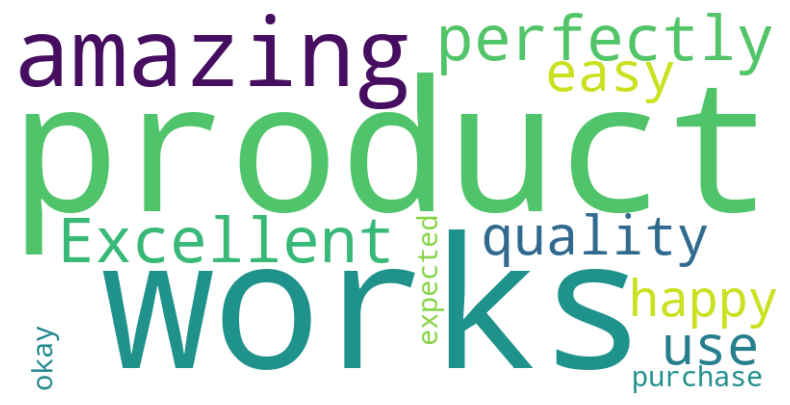

In [9]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This product is amazing and works perfectly",
    "Excellent quality and very easy to use",
    "I am very happy with this purchase",
    "The product is terrible and disappointing",
    "Poor quality and very bad performance",
    "The product is okay and works as expected"
]

positive_reviews = []

for review in reviews:
    sentiment = TextBlob(review).sentiment
    polarity = sentiment.polarity
    subjectivity = sentiment.subjectivity

    if polarity > 0:
        category = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        category = "Negative"
    else:
        category = "Neutral"

    print("Review:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", category)
    print()

wordcloud = WordCloud(width=800, height=400, background_color="white").generate(" ".join(positive_reviews))

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

In [12]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


Question 6

In [15]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """Artificial intelligence is transforming the modern world.
Artificial intelligence helps machines learn from data and solve complex problems.
Machine learning is an important part of artificial intelligence.
Deep learning uses neural networks to recognize patterns.
Technology improves healthcare education and communication.
Computers can analyze information and make useful predictions.
Artificial intelligence supports automation and innovation.
Data science helps organizations understand information.
Smart systems are becoming common in everyday life.
Artificial intelligence continues to develop and create new opportunities."""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
sequences = []

for line in text.split("."):
    tokens = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(tokens) + 1):
        sequences.append(tokens[:i])

max_sequence_len = max(len(seq) for seq in sequences)
sequences = np.array(pad_sequences(sequences, maxlen=max_sequence_len, padding="pre"))

X = sequences[:, :-1]
y = sequences[:, -1]

model = Sequential([
    Embedding(total_words, 32),
    LSTM(32),
    Dense(total_words, activation="softmax")
])

model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

model.fit(X, y, epochs=30, verbose=1)

def generate_text(seed_text, next_words):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_sequence_len - 1, padding="pre")
        predicted = np.argmax(model.predict(token_list, verbose=0), axis=1)[0]
        output_word = tokenizer.index_word.get(predicted, "")

        if not output_word:
            break

        seed_text += " " + output_word

    return seed_text

print("\nGenerated Text:")
print(generate_text("artificial intelligence", 8))
print(generate_text("machine learning", 8))
print(generate_text("technology", 8))

Epoch 1/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.0000e+00 - loss: 4.1112
Epoch 2/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.0441 - loss: 4.1059 
Epoch 3/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.0882 - loss: 4.1024
Epoch 4/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.0882 - loss: 4.0989
Epoch 5/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.1029 - loss: 4.0950
Epoch 6/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.1029 - loss: 4.0908
Epoch 7/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.1029 - loss: 4.0866
Epoch 8/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.1324 - loss: 4.0818
Epoch 9/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.1176 - loss: 4.0768
Epoch 10/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.1176 - loss: 4.0712
Epoch 11/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.1176 - loss: 4.0639
Epoch 12/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.1176 - loss: 4.0